# Chapter 19: Stochastic Differential Equations (SDEs)
## Interactive Python & PyTorch Companion Notebook

Welcome to the companion coding notebook for **Chapter 19: Stochastic Differential Equations**. In this notebook, we verify the analytical results from the lecture and exercises through numerical simulation and visualization:

1. **Exercise 1 (Brownian Motion & Quadratic Variation):** Simulating 1D Brownian motion $W_t$, computing discrete $p$-variation sums ($p \in \{1, 2, 3\}$), and verifying $Q_n \to T$ almost surely as $n \to \infty$ with $\mathrm{Var}(Q_n) = 2T^2/n$.
2. **Exercise 2 (Itô SDE & Discretization):** One Euler–Maruyama step of geometric Brownian motion (conditional mean $(1+\mu\Delta t)X_k$, variance $\sigma^2X_k^2\Delta t$), and the moments $\Delta t$, $2\Delta t^2$ of squared increments.
3. **Exercise 3 (Itô's Lemma):** The GBM median-vs-mean paradox, $\int_0^t W\,dW = \frac12(W_t^2 - t)$ and its variance $t^2/2$, the Stratonovich integral $\frac12W_t^2$, $\mathbb{E}[e^{W_t}] = e^{t/2}$, and $\mathrm{Var}\int_0^t s\,dW_s = t^3/3$.
4. **Exercise 4 (Reverse-Time SDE):** The Gaussian reverse drift $x/(s^2+t)$ and the two-mode bound $x\,b(x) \ge |x|(|x|-m)/v$.
5. **Exercise 5 (The VP-SDE from Itô's Lemma):** The VP transition $\mathcal{N}(e^{-\beta t/2}X_0, 1-e^{-\beta t})$, checked by simulation, and the reverse-time SDE and probability flow ODE on a bimodal Gaussian mixture with exact scores.

In [1]:
import numpy as np
import torch
import matplotlib.pyplot as plt

# Configure Matplotlib for crisp, publication-quality figures
plt.rcParams.update({
    "figure.dpi": 120,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "font.size": 10,
})

np.random.seed(42)
torch.manual_seed(42)
print("Environment initialized successfully.")

Environment initialized successfully.


---
## 1. Exercise 1: Brownian Motion & Quadratic Variation

A standard 1D Brownian motion $W_t$ on $[0, T]$ has independent Gaussian increments $\Delta W_k = W_{t_k} - W_{t_{k-1}} \sim \mathcal{N}(0, \Delta t)$ where $\Delta t = T/n$.

### Key Analytical Properties
1. **Covariance:** $\mathrm{Cov}(W_s, W_t) = \min(s, t)$.
2. **Quadratic Variation ($p=2$):** For $Q_n = \sum_{k=1}^n (\Delta W_k)^2$,
   $$\mathbb{E}[Q_n] = n \Delta t = T, \qquad \mathrm{Var}(Q_n) = n \cdot 2(\Delta t)^2 = \frac{2T^2}{n} \xrightarrow{n\to\infty} 0.$$
   Hence $Q_n \to T$ in $L^2(\Omega)$ (and almost surely along dyadic partitions), justifying the formal differential rule $(dW_t)^2 = dt$.
3. **Unbounded Total Variation ($p=1$) & Vanishing Cubic Variation ($p=3$):**
   $$\mathbb{E}\!\left[\sum_{k=1}^n |\Delta W_k|\right] = \sqrt{\frac{2}{\pi}}\,T\sqrt{n} \to \infty, \qquad \mathbb{E}\!\left[\sum_{k=1}^n |\Delta W_k|^3\right] = 2\sqrt{\frac{2}{\pi}}\,\frac{T^{3/2}}{\sqrt{n}} \to 0.$$

Covariance check at s=0.75, t=1.50:
  Empirical Cov(W_s, W_t) = 0.7026 | Exact min(s, t) = 0.7500



At finest partition n = 16384:
  Mean Quadratic Variation E[Q_n] = 2.00034 (Exact T = 2.00000)
  Var(Q_n)                        = 0.000455 (Exact 2T^2/n = 0.000488)


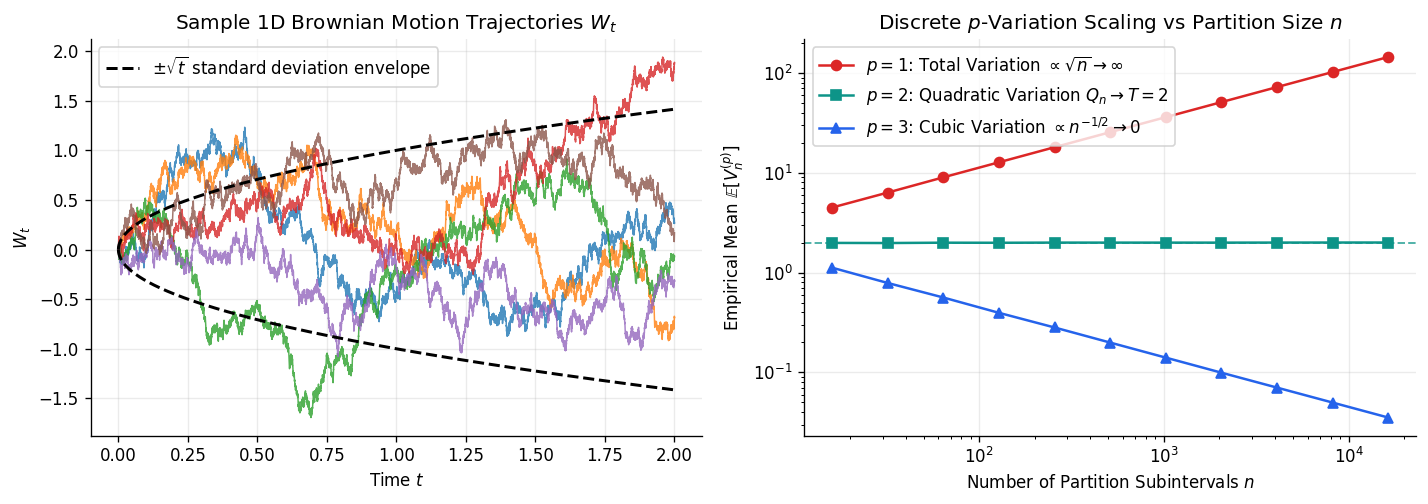

In [2]:
# Simulate Brownian paths and verify p-variation scaling laws
T = 2.0
n_fine = 16384
dt_fine = T / n_fine
n_paths = 1000

# Fine-grid Brownian increments: shape (n_paths, n_fine)
dW_fine = np.sqrt(dt_fine) * np.random.randn(n_paths, n_fine)
W_fine = np.hstack([np.zeros((n_paths, 1)), np.cumsum(dW_fine, axis=1)])
t_grid = np.linspace(0.0, T, n_fine + 1)

# Verify covariance Cov(W_s, W_t) = min(s, t) at s=0.75, t=1.50
idx_s = int(0.75 / dt_fine)
idx_t = int(1.50 / dt_fine)
emp_cov = np.cov(W_fine[:, idx_s], W_fine[:, idx_t])[0, 1]
print(f"Covariance check at s=0.75, t=1.50:")
print(f"  Empirical Cov(W_s, W_t) = {emp_cov:.4f} | Exact min(s, t) = {min(0.75, 1.50):.4f}")

# Dyadic refinement: n = 2^4 to 2^14
dyadic_exponents = np.arange(4, 15)
n_values = 2 ** dyadic_exponents
v1_means, v2_means, v2_vars, v3_means = [], [], [], []

for n_sub in n_values:
    stride = n_fine // n_sub
    W_sub = W_fine[:, ::stride]
    dW_sub = np.diff(W_sub, axis=1)
    
    v1 = np.sum(np.abs(dW_sub), axis=1)
    v2 = np.sum(dW_sub ** 2, axis=1)
    v3 = np.sum(np.abs(dW_sub) ** 3, axis=1)
    
    v1_means.append(np.mean(v1))
    v2_means.append(np.mean(v2))
    v2_vars.append(np.var(v2))
    v3_means.append(np.mean(v3))

print(f"\nAt finest partition n = {n_fine}:")
print(f"  Mean Quadratic Variation E[Q_n] = {v2_means[-1]:.5f} (Exact T = {T:.5f})")
print(f"  Var(Q_n)                        = {v2_vars[-1]:.6f} (Exact 2T^2/n = {2*T**2/n_fine:.6f})")

# Plot sample paths + p-variation convergence
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))

for i in range(6):
    axes[0].plot(t_grid, W_fine[i], lw=0.9, alpha=0.8)
axes[0].plot(t_grid, np.sqrt(t_grid), "k--", lw=1.8, label=r"$\pm\sqrt{t}$ standard deviation envelope")
axes[0].plot(t_grid, -np.sqrt(t_grid), "k--", lw=1.8)
axes[0].set_title("Sample 1D Brownian Motion Trajectories $W_t$")
axes[0].set_xlabel("Time $t$")
axes[0].set_ylabel("$W_t$")
axes[0].legend(loc="upper left")

axes[1].loglog(n_values, v1_means, "o-", color="#dc2626", label=r"$p=1$: Total Variation $\propto \sqrt{n} \to \infty$")
axes[1].loglog(n_values, v2_means, "s-", color="#0d9488", label=r"$p=2$: Quadratic Variation $Q_n \to T = 2$")
axes[1].loglog(n_values, v3_means, "^-", color="#2563eb", label=r"$p=3$: Cubic Variation $\propto n^{-1/2} \to 0$")
axes[1].axhline(T, color="#0d9488", ls="--", lw=1.2, alpha=0.7)
axes[1].set_title(r"Discrete $p$-Variation Scaling vs Partition Size $n$")
axes[1].set_xlabel(r"Number of Partition Subintervals $n$")
axes[1].set_ylabel(r"Empirical Mean $\mathbb{E}[V_n^{(p)}]$")
axes[1].legend(loc="best")

plt.tight_layout()
plt.show()

---
## 2. Exercise 2: Itô SDE & Euler–Maruyama Discretization

1. **Euler–Maruyama for geometric Brownian motion** $dX_t = \mu X_t\,dt + \sigma X_t\,dW_t$:
   $$X_{k+1} = X_k\big(1 + \mu\Delta t + \sigma\sqrt{\Delta t}\,\xi_k\big), \qquad \mathbb{E}[X_{k+1}\mid X_k] = (1 + \mu\Delta t)X_k, \qquad \mathrm{Var}(X_{k+1}\mid X_k) = \sigma^2X_k^2\Delta t.$$
2. **Squared increments** $\Delta W \sim \mathcal{N}(0, \Delta t)$: $\mathbb{E}[(\Delta W)^2] = \Delta t$ and $\mathrm{Var}\big((\Delta W)^2\big) = 2\Delta t^2$.


In [3]:
# Exercise 2: one Euler-Maruyama step of GBM, and squared Brownian increments
rng2 = np.random.default_rng(2)
mu_g, sig_g, dt_g, x_k = 0.3, 0.5, 0.01, 2.0
x_next = x_k * (1 + mu_g * dt_g + sig_g * np.sqrt(dt_g) * rng2.standard_normal(1_000_000))
print(f"[Ex 2.1] E[X_k+1 | X_k] = {x_next.mean():.5f}   (formula (1 + mu dt) X_k = {(1 + mu_g * dt_g) * x_k:.5f})")
print(f"[Ex 2.1] Var(X_k+1 | X_k) = {x_next.var():.6f}  (formula sigma^2 X_k^2 dt = {sig_g**2 * x_k**2 * dt_g:.6f})")

dW = np.sqrt(dt_g) * rng2.standard_normal(1_000_000)
print(f"[Ex 2.2] E[(dW)^2] = {np.mean(dW**2):.6f} (dt = {dt_g}),  Var((dW)^2) = {np.var(dW**2):.3e} (2 dt^2 = {2 * dt_g**2:.3e})")

# Summed squares over [0, T] concentrate at T as dt -> 0
T_q = 2.0
for n in (10, 100, 1000):
    q = np.sum((np.sqrt(T_q / n) * rng2.standard_normal((5000, n))) ** 2, axis=1)
    print(f"[Ex 2.2] n = {n:5d}: sum (dW)^2 has mean {q.mean():.4f} and variance {q.var():.5f} (2 T dt = {2 * T_q * T_q / n:.5f})")


[Ex 2.1] E[X_k+1 | X_k] = 2.00610   (formula (1 + mu dt) X_k = 2.00600)
[Ex 2.1] Var(X_k+1 | X_k) = 0.009999  (formula sigma^2 X_k^2 dt = 0.010000)
[Ex 2.2] E[(dW)^2] = 0.009994 (dt = 0.01),  Var((dW)^2) = 1.995e-04 (2 dt^2 = 2.000e-04)
[Ex 2.2] n =    10: sum (dW)^2 has mean 2.0142 and variance 0.82124 (2 T dt = 0.80000)
[Ex 2.2] n =   100: sum (dW)^2 has mean 1.9979 and variance 0.07923 (2 T dt = 0.08000)
[Ex 2.2] n =  1000: sum (dW)^2 has mean 2.0011 and variance 0.00787 (2 T dt = 0.00800)


---
## 3. Exercise 3: Itô's Lemma & Geometric Brownian Motion

For $dX_t = \mu(X_t, t)\,dt + \sigma(X_t, t)\,dW_t$ and smooth $f(x, t)$, **Itô's Lemma** gives:
$$df(X_t, t) = \left(\frac{\partial f}{\partial t} + \mu\frac{\partial f}{\partial x} + \frac{1}{2}\sigma^2\frac{\partial^2 f}{\partial x^2}\right)dt + \sigma\frac{\partial f}{\partial x}\,dW_t.$$

### Geometric Brownian Motion (GBM) Paradox
For $dS_t = \mu S_t\,dt + \sigma S_t\,dW_t$, applying Itô's lemma to $f(s) = \ln s$ ($f''(s) = -1/s^2$) yields:
$$d(\ln S_t) = \left(\mu - \frac{1}{2}\sigma^2\right)dt + \sigma\,dW_t \implies S_t = S_0 \exp\!\left(\left(\mu - \frac{1}{2}\sigma^2\right)t + \sigma W_t\right).$$
When $0 < \mu < \frac{1}{2}\sigma^2$:
- The **expected value** grows exponentially: $\mathbb{E}[S_t] = S_0 e^{\mu t} \to \infty$.
- The **median trajectory** decays to zero: $\mathrm{Median}(S_t) = S_0 e^{(\mu - \frac{1}{2}\sigma^2)t} \to 0$.

At terminal time T = 10.0:
  Empirical Mean E[S_T]     = 13.5677 | Exact S0*exp(mu*T)                = 4.4817
  Empirical Median Med(S_T) = 0.1763 | Exact S0*exp((mu - 0.5*sigma^2)T) = 0.1827
  Fraction of paths with S_T < S_0: 75.3%


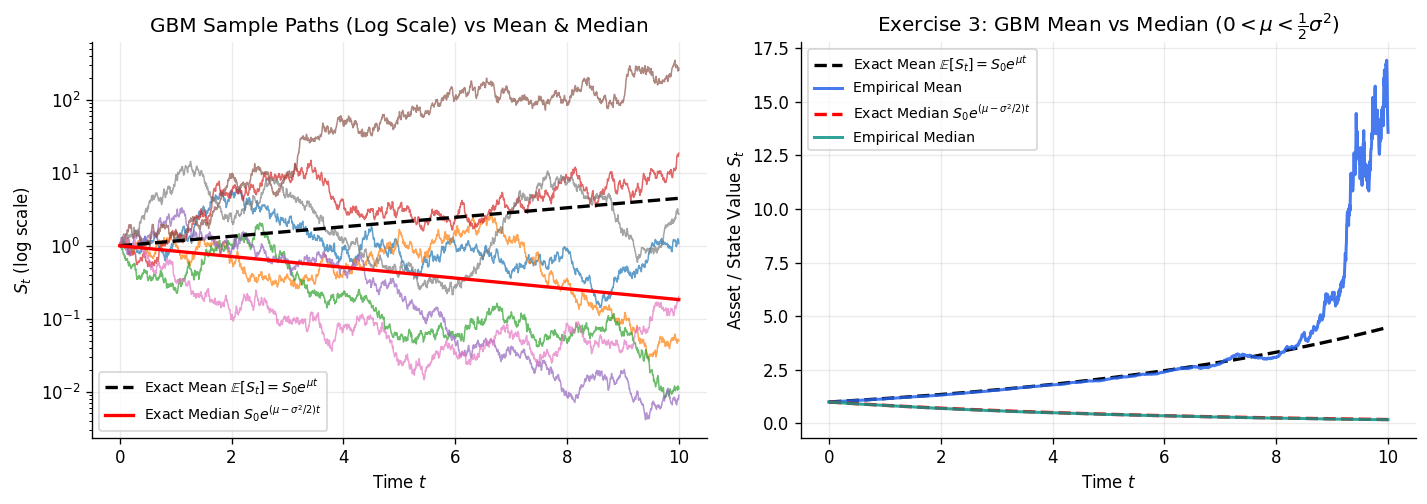

In [4]:
# Simulate GBM in the regime 0 < mu < 0.5 * sigma^2
S0 = 1.0
mu_gbm = 0.15
sigma_gbm = 0.80  # 0.5 * sigma^2 = 0.32 > mu = 0.15
T_gbm = 10.0
n_steps_gbm = 2000
dt_gbm = T_gbm / n_steps_gbm
n_paths_gbm = 20000

t_gbm = np.linspace(0.0, T_gbm, n_steps_gbm + 1)
dW_gbm = np.sqrt(dt_gbm) * np.random.randn(n_paths_gbm, n_steps_gbm)
W_gbm = np.hstack([np.zeros((n_paths_gbm, 1)), np.cumsum(dW_gbm, axis=1)])

# Exact GBM trajectories via Ito's Lemma
S_paths = S0 * np.exp((mu_gbm - 0.5 * sigma_gbm ** 2) * t_gbm[None, :] + sigma_gbm * W_gbm)

emp_mean_S = np.mean(S_paths, axis=0)
emp_median_S = np.median(S_paths, axis=0)
exact_mean_S = S0 * np.exp(mu_gbm * t_gbm)
exact_median_S = S0 * np.exp((mu_gbm - 0.5 * sigma_gbm ** 2) * t_gbm)

print(f"At terminal time T = {T_gbm}:")
print(f"  Empirical Mean E[S_T]     = {emp_mean_S[-1]:.4f} | Exact S0*exp(mu*T)                = {exact_mean_S[-1]:.4f}")
print(f"  Empirical Median Med(S_T) = {emp_median_S[-1]:.4f} | Exact S0*exp((mu - 0.5*sigma^2)T) = {exact_median_S[-1]:.4f}")
print(f"  Fraction of paths with S_T < S_0: {np.mean(S_paths[:, -1] < S0)*100:.1f}%")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))

for i in range(8):
    axes[0].plot(t_gbm, S_paths[i], lw=0.9, alpha=0.7)
axes[0].plot(t_gbm, exact_mean_S, "k--", lw=2.0, label=r"Exact Mean $\mathbb{E}[S_t] = S_0 e^{\mu t}$")
axes[0].plot(t_gbm, exact_median_S, "r-", lw=2.0, label=r"Exact Median $S_0 e^{(\mu - \sigma^2/2)t}$")
axes[0].set_yscale("log")
axes[0].set_title("GBM Sample Paths (Log Scale) vs Mean & Median")
axes[0].set_xlabel("Time $t$")
axes[0].set_ylabel("$S_t$ (log scale)")
axes[0].legend(loc="lower left", fontsize=8.5)

axes[1].plot(t_gbm, exact_mean_S, "k--", lw=2.0, label=r"Exact Mean $\mathbb{E}[S_t] = S_0 e^{\mu t}$")
axes[1].plot(t_gbm, emp_mean_S, color="#2563eb", lw=1.8, alpha=0.85, label="Empirical Mean")
axes[1].plot(t_gbm, exact_median_S, "r--", lw=2.0, label=r"Exact Median $S_0 e^{(\mu - \sigma^2/2)t}$")
axes[1].plot(t_gbm, emp_median_S, color="#0d9488", lw=1.8, alpha=0.85, label="Empirical Median")
axes[1].set_title(r"Exercise 3: GBM Mean vs Median ($0 < \mu < \frac{1}{2}\sigma^2$)")
axes[1].set_xlabel("Time $t$")
axes[1].set_ylabel("Asset / State Value $S_t$")
axes[1].legend(loc="upper left", fontsize=8.5)

plt.tight_layout()
plt.show()

In [5]:
# Exercise 3, parts 3-8: Ito integrals of Brownian motion
rng3 = np.random.default_rng(3)
t_end, n_s, M = 1.0, 2000, 20000
dWs = np.sqrt(t_end / n_s) * rng3.standard_normal((M, n_s))
W = np.cumsum(dWs, axis=1)
W_left = np.hstack([np.zeros((M, 1)), W[:, :-1]])
s_left = np.arange(n_s) * t_end / n_s

ito = np.sum(W_left * dWs, axis=1)                       # int W dW (left endpoint)
strat = np.sum(0.5 * (W_left + W) * dWs, axis=1)         # midpoint sums
print(f"[Ex 3.3] max |Ito sum - (W_t^2 - t)/2| = {np.max(np.abs(ito - (W[:, -1]**2 - t_end) / 2)):.3f}")
print(f"[Ex 3.4] mean {ito.mean():+.4f} (0), variance {ito.var():.4f} (t^2/2 = {t_end**2 / 2})")
print(f"[Ex 3.5] max |Stratonovich sum - W_t^2/2| = {np.max(np.abs(strat - W[:, -1]**2 / 2)):.1e}  (telescopes exactly)")
print(f"[Ex 3.6] E[exp(W_t)] = {np.exp(W[:, -1]).mean():.4f}  (e^(t/2) = {np.exp(t_end / 2):.4f})")
int_s = np.sum(s_left * dWs, axis=1)
by_parts = t_end * W[:, -1] - np.sum(W_left, axis=1) * t_end / n_s
print(f"[Ex 3.7] max |int s dW - (t W_t - int W ds)| = {np.max(np.abs(int_s - by_parts)):.3f}")
print(f"[Ex 3.8] Var(int s dW) = {int_s.var():.4f}  (t^3/3 = {t_end**3 / 3:.4f})")


[Ex 3.3] max |Ito sum - (W_t^2 - t)/2| = 0.064
[Ex 3.4] mean +0.0058 (0), variance 0.5099 (t^2/2 = 0.5)
[Ex 3.5] max |Stratonovich sum - W_t^2/2| = 3.6e-14  (telescopes exactly)
[Ex 3.6] E[exp(W_t)] = 1.6749  (e^(t/2) = 1.6487)
[Ex 3.7] max |int s dW - (t W_t - int W ds)| = 0.002
[Ex 3.8] Var(int s dW) = 0.3354  (t^3/3 = 0.3333)


---
## 4. Exercises 4 & 5: Reverse-Time Drifts & the VP-SDE

### Exercise 4: Reverse-Time Drifts for $dX_t = dW_t$
1. **Gaussian start** $X_0 \sim \mathcal{N}(0, s^2)$: $p_t = \mathcal{N}(0, s^2 + t)$ and the reverse drift is $b(x) = -\partial_x\log p_t(x) = x/(s^2 + t)$.
2. **Two modes** $p_t = \frac12\mathcal{N}(\pm m, v)$: $b(x) = \frac{x}{v} - \frac{m}{v}\tanh\frac{mx}{v}$ satisfies $x\,b(x) \ge |x|(|x| - m)/v > 0$ for $|x| > m$.

### Exercise 5: The VP-SDE from Itô's Lemma
For $dX_t = -\frac12\beta X_t\,dt + \sqrt\beta\,dW_t$, the integrating factor $e^{\beta t/2}$ gives $X_t \mid X_0 \sim \mathcal{N}(e^{-\beta t/2}X_0,\ 1 - e^{-\beta t})$, and for a Gaussian mixture start every marginal is a Gaussian mixture with exact score. With $\beta = 1$ we integrate backward:
1. **Reverse-Time SDE:** $d\bar{X}_\tau = \left[\frac{1}{2}\bar{X}_\tau + \nabla_x \log p_{T-\tau}(\bar{X}_\tau)\right]d\tau + d\bar{W}_\tau$,
2. **Probability Flow ODE:** $\frac{d\bar{x}_\tau}{d\tau} = \frac{1}{2}\bar{x}_\tau + \frac{1}{2}\nabla_x \log p_{T-\tau}(\bar{x}_\tau)$,
from $\tau = 0$ ($t = T$) back to $\tau = T$ ($t = 0$).


[Ex 4.1] Var(X_t) = 0.9881 (s^2 + t = 0.9900); reverse drift x/Var at x = [-1.   0.5  1.5]: [-1.012  0.506  1.518]  vs  x/(s^2+t) = [-1.01   0.505  1.515]
[Ex 4.2] min over |x| > m of x b(x) - |x|(|x|-m)/v = 1.4e-14  (>= 0)


[Ex 5.2] mean 0.8090 (e^(-beta t/2) x0 = 0.8131), variance 0.8414 (1 - e^(-beta t) = 0.8347)


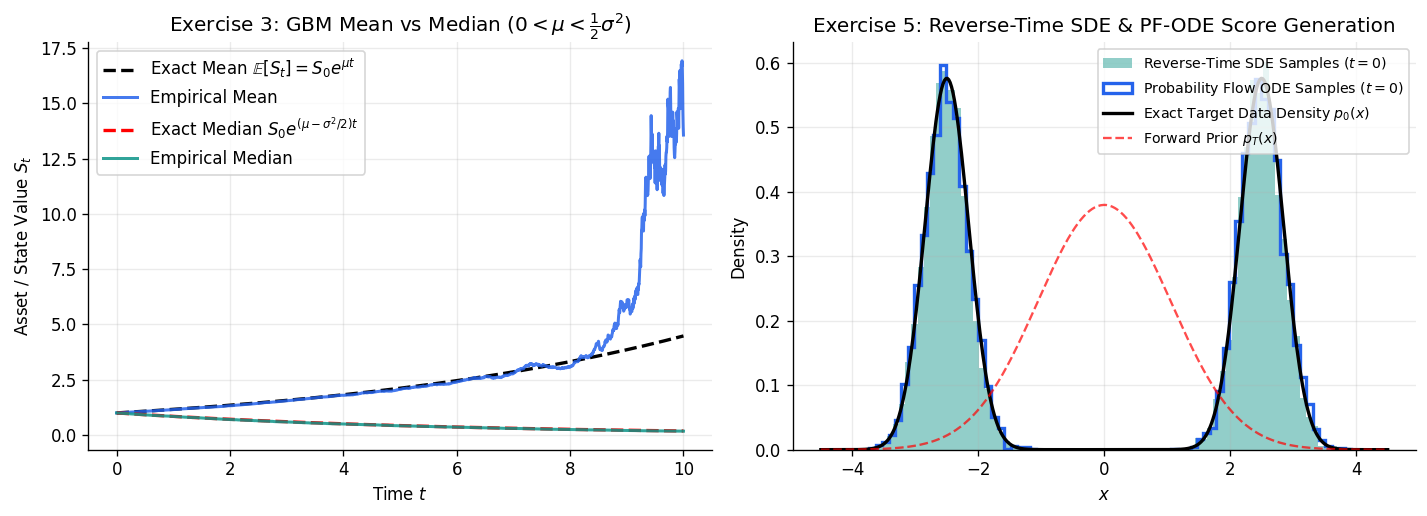

In [6]:
# Part A: Exercise 4 (reverse drifts) and Exercise 5 (VP transition)
rng4 = np.random.default_rng(4)
s_g, t_g = 0.7, 0.5
xg = rng4.normal(0, s_g, 2_000_000) + rng4.normal(0, np.sqrt(t_g), 2_000_000)   # X_t = X_0 + W_t
xs = np.array([-1.0, 0.5, 1.5])
print(f"[Ex 4.1] Var(X_t) = {xg.var():.4f} (s^2 + t = {s_g**2 + t_g:.4f}); reverse drift x/Var at x = {xs}: "
      f"{(xs / xg.var()).round(3)}  vs  x/(s^2+t) = {(xs / (s_g**2 + t_g)).round(3)}")
m_b, v_b = 1.3, 0.6
xx = np.concatenate([np.linspace(m_b + 1e-4, 8, 2000), -np.linspace(m_b + 1e-4, 8, 2000)])
bb = xx / v_b - (m_b / v_b) * np.tanh(m_b * xx / v_b)
print(f"[Ex 4.2] min over |x| > m of x b(x) - |x|(|x|-m)/v = {np.min(xx * bb - np.abs(xx) * (np.abs(xx) - m_b) / v_b):.1e}  (>= 0)")

beta5, t5, x05, n5 = 1.5, 1.2, 2.0, 1200
xv = np.full(40000, x05)
for _ in range(n5):
    xv = xv - 0.5 * beta5 * xv * (t5 / n5) + np.sqrt(beta5 * t5 / n5) * rng4.standard_normal(40000)
print(f"[Ex 5.2] mean {xv.mean():.4f} (e^(-beta t/2) x0 = {np.exp(-beta5 * t5 / 2) * x05:.4f}), "
      f"variance {xv.var():.4f} (1 - e^(-beta t) = {1 - np.exp(-beta5 * t5):.4f})")

# Part B: Exercise 5 (Reverse-Time SDE & Probability Flow ODE on 1D Gaussian Mixture, beta = 1)
m1, m2 = -2.5, 2.5
w1, w2 = 0.5, 0.5
v0 = 0.12
T_diff = 4.0
n_steps_diff = 1000
dt_diff = T_diff / n_steps_diff

def exact_gmm_density_and_score(x, t):
    '''Compute exact marginal density p_t(x) and score d/dx log p_t(x) at time t.'''
    alpha_t = np.exp(-0.5 * t)
    v_t = v0 * np.exp(-t) + (1.0 - np.exp(-t))
    
    mu1_t = m1 * alpha_t
    mu2_t = m2 * alpha_t
    
    p1 = (w1 / np.sqrt(2.0 * np.pi * v_t)) * np.exp(-0.5 * ((x - mu1_t) ** 2) / v_t)
    p2 = (w2 / np.sqrt(2.0 * np.pi * v_t)) * np.exp(-0.5 * ((x - mu2_t) ** 2) / v_t)
    p_total = p1 + p2 + 1e-15
    
    grad_p1 = -((x - mu1_t) / v_t) * p1
    grad_p2 = -((x - mu2_t) / v_t) * p2
    score = (grad_p1 + grad_p2) / p_total
    return p_total, score

# Sample terminal prior at t = T_diff
n_gen = 8000
_, _ = exact_gmm_density_and_score(0.0, T_diff)
alpha_T = np.exp(-0.5 * T_diff)
v_T = v0 * np.exp(-T_diff) + (1.0 - np.exp(-T_diff))
comp_choice = (np.random.rand(n_gen) < w1)
x_init_T = np.where(comp_choice, m1 * alpha_T, m2 * alpha_T) + np.sqrt(v_T) * np.random.randn(n_gen)

x_rev_sde = x_init_T.copy()
x_pf_ode = x_init_T.copy()

# Integrate backwards from t = T_diff to t = 0
for step in range(n_steps_diff):
    t_curr = T_diff - step * dt_diff
    _, score_sde = exact_gmm_density_and_score(x_rev_sde, t_curr)
    _, score_ode = exact_gmm_density_and_score(x_pf_ode, t_curr)
    
    # Reverse-Time SDE step
    x_rev_sde = x_rev_sde + (0.5 * x_rev_sde + score_sde) * dt_diff + np.sqrt(dt_diff) * np.random.randn(n_gen)
    # Probability Flow ODE step
    x_pf_ode = x_pf_ode + (0.5 * x_pf_ode + 0.5 * score_ode) * dt_diff

# Plot GBM Paradox (Left) and Reverse-Time SDE / PF-ODE Generation (Right)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))

axes[0].plot(t_gbm, exact_mean_S, "k--", lw=2, label=r"Exact Mean $\mathbb{E}[S_t] = S_0 e^{\mu t}$")
axes[0].plot(t_gbm, emp_mean_S, color="#2563eb", lw=1.8, alpha=0.85, label="Empirical Mean")
axes[0].plot(t_gbm, exact_median_S, "r--", lw=2, label=r"Exact Median $S_0 e^{(\mu - \sigma^2/2)t}$")
axes[0].plot(t_gbm, emp_median_S, color="#0d9488", lw=1.8, alpha=0.85, label="Empirical Median")
axes[0].set_title(r"Exercise 3: GBM Mean vs Median ($0 < \mu < \frac{1}{2}\sigma^2$)")
axes[0].set_xlabel("Time $t$")
axes[0].set_ylabel("Asset / State Value $S_t$")
axes[0].legend(loc="upper left")

x_grid = np.linspace(-4.5, 4.5, 400)
p0_exact, _ = exact_gmm_density_and_score(x_grid, 0.0)
pT_exact, _ = exact_gmm_density_and_score(x_grid, T_diff)

axes[1].hist(x_rev_sde, bins=75, density=True, alpha=0.45, color="#0d9488", label="Reverse-Time SDE Samples ($t=0$)")
axes[1].hist(x_pf_ode, bins=75, density=True, histtype="step", lw=2.0, color="#2563eb", label="Probability Flow ODE Samples ($t=0$)")
axes[1].plot(x_grid, p0_exact, "k-", lw=2.0, label="Exact Target Data Density $p_0(x)$")
axes[1].plot(x_grid, pT_exact, "r--", lw=1.4, alpha=0.7, label="Forward Prior $p_T(x)$")
axes[1].set_title("Exercise 5: Reverse-Time SDE & PF-ODE Score Generation")
axes[1].set_xlabel("$x$")
axes[1].set_ylabel("Density")
axes[1].legend(loc="upper right", fontsize=8.5)

plt.tight_layout()
plt.show()

---
## Experiment 5 (Lab 5 - Hard): Itô vs. Stratonovich Integration & The Wong–Zakai Correction

### Mathematical Formulation
Stochastic differential equations (SDEs) with state-dependent diffusion $\sigma(\mathbf{x})$ depend fundamentally on the evaluation point of the stochastic integral:
- **Itô SDE (Left-endpoint rule $\tau_i = t_i$)**:
  $$dX_t = \mu(X_t)\,dt + \sigma(X_t)\,dW_t \implies \int_0^t \sigma(X_s)\,dW_s = \lim_{N\to\infty} \sum_{i=0}^{N-1} \sigma(X_{t_i})\,(W_{t_{i+1}} - W_{t_i})$$
  - Possesses the **martingale property**: $\mathbb{E}\left[\int_0^t \sigma(X_s)\,dW_s\right] = 0$.
  - Preserves standard non-anticipating information filtration (ideal for finance & causal filtering).
- **Stratonovich SDE (Midpoint rule $\tau_i = \frac{t_i + t_{i+1}}{2}$)**:
  $$dX_t = \mu(X_t)\,dt + \sigma(X_t) \circ dW_t \implies \int_0^t \sigma(X_s) \circ dW_s = \lim_{N\to\infty} \sum_{i=0}^{N-1} \sigma\left(\frac{X_{t_i} + X_{t_{i+1}}}{2}\right)\,(W_{t_{i+1}} - W_{t_i})$$
  - Obeys the standard chain rule of classical calculus ($d(f(X_t)) = f'(X_t) \circ dX_t$, no Hessian term).
  - Emerges as the physical limit of smooth colored noise as correlation time $\tau \to 0$ (**Wong–Zakai theorem**).
- **Itô–Stratonovich Conversion Formula**:
  $$dX_t = \underbrace{\left(\mu(X_t) + \frac{1}{2}\sigma(X_t)\sigma'(X_t)\right)}_{\text{Equivalent Itô Drift}}\,dt + \sigma(X_t)\,dW_t$$
  where $\frac{1}{2}\sigma(x)\sigma'(x)$ is the **Stratonovich-to-Itô drift correction wedge**.


Final Itô Mean:         2.7372 (Theory = 2.7183)
Final Stratonovich Mean: 3.9239 (Theory = 3.8962)
Drift Wedge Gap:        1.1867 (Theory = 1.1779)


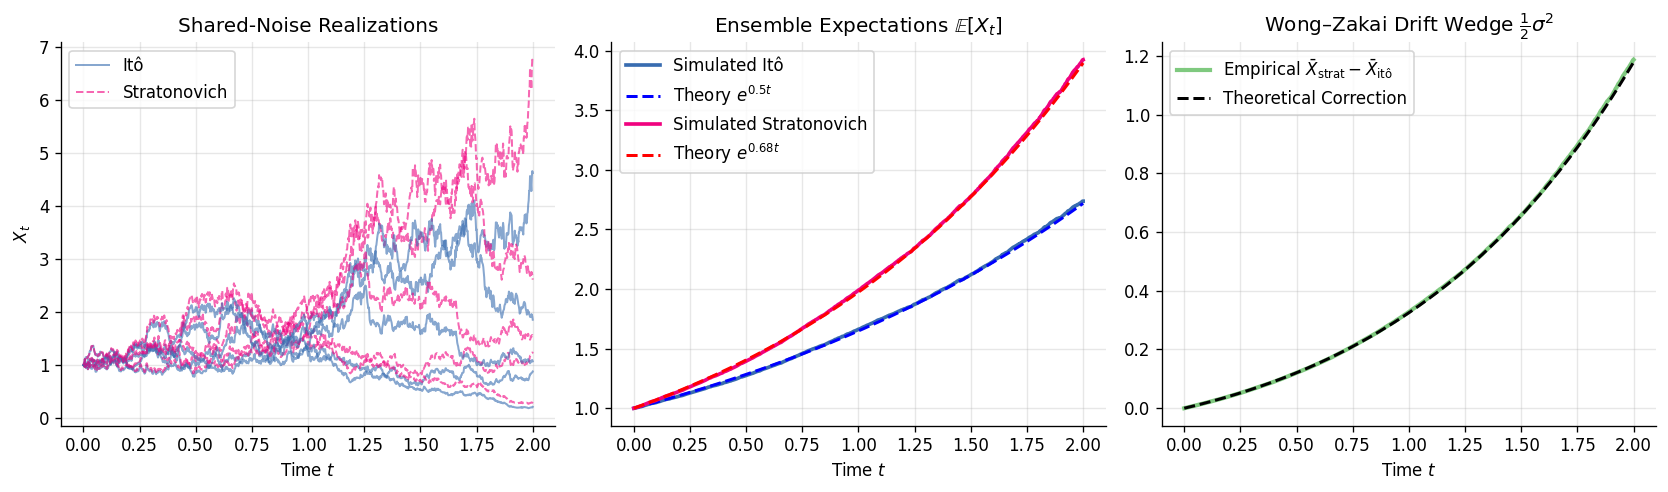

In [7]:
# Lab 5: Itô vs. Stratonovich Discrepancy under Identical Brownian Realizations
rng = np.random.default_rng(42)
T = 2.0
N_steps = 1000
dt = T / N_steps
t_grid = np.linspace(0, T, N_steps + 1)
N_paths = 4000
X0 = 1.0
mu = 0.5
sigma = 0.6

# Generate shared Brownian increments dW
dW = np.sqrt(dt) * rng.normal(size=(N_paths, N_steps))

X_ito = np.zeros((N_paths, N_steps + 1))
X_strat = np.zeros((N_paths, N_steps + 1))
X_ito[:, 0] = X0
X_strat[:, 0] = X0

for i in range(N_steps):
    dw = dW[:, i]
    # Euler-Maruyama for Itô: evaluation at left endpoint X_n
    X_ito[:, i+1] = X_ito[:, i] + mu * X_ito[:, i] * dt + sigma * X_ito[:, i] * dw
    
    # Heun predictor-corrector for Stratonovich: midpoint approximation
    x_c = X_strat[:, i]
    x_pred = x_c + mu * x_c * dt + sigma * x_c * dw
    X_strat[:, i+1] = x_c + 0.5 * (mu * x_c + mu * x_pred) * dt + 0.5 * sigma * (x_c + x_pred) * dw

mean_ito = np.mean(X_ito, axis=0)
mean_strat = np.mean(X_strat, axis=0)
theory_ito = X0 * np.exp(mu * t_grid)
theory_strat = X0 * np.exp((mu + 0.5 * sigma**2) * t_grid)

print(f"Final Itô Mean:         {mean_ito[-1]:.4f} (Theory = {theory_ito[-1]:.4f})")
print(f"Final Stratonovich Mean: {mean_strat[-1]:.4f} (Theory = {theory_strat[-1]:.4f})")
print(f"Drift Wedge Gap:        {mean_strat[-1] - mean_ito[-1]:.4f} (Theory = {theory_strat[-1] - theory_ito[-1]:.4f})")

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
for p in range(5):
    axes[0].plot(t_grid, X_ito[p], color='#386cb0', alpha=0.6, lw=1.2, label='Itô' if p == 0 else "")
    axes[0].plot(t_grid, X_strat[p], color='#f0027f', alpha=0.6, lw=1.2, linestyle='--', label='Stratonovich' if p == 0 else "")
axes[0].set_title("Shared-Noise Realizations")
axes[0].set_xlabel("Time $t$"); axes[0].set_ylabel("$X_t$")
axes[0].legend(loc='upper left'); axes[0].grid(True, alpha=0.3)

axes[1].plot(t_grid, mean_ito, color='#386cb0', lw=2.2, label='Simulated Itô')
axes[1].plot(t_grid, theory_ito, 'b--', lw=1.8, label=f'Theory $e^{{{mu}t}}$')
axes[1].plot(t_grid, mean_strat, color='#f0027f', lw=2.2, label='Simulated Stratonovich')
axes[1].plot(t_grid, theory_strat, 'r--', lw=1.8, label=f'Theory $e^{{{mu + 0.5*sigma**2:.2f}t}}$')
axes[1].set_title("Ensemble Expectations $\\mathbb{E}[X_t]$")
axes[1].set_xlabel("Time $t$"); axes[1].legend(loc='upper left'); axes[1].grid(True, alpha=0.3)

axes[2].plot(t_grid, mean_strat - mean_ito, color='#7fc97f', lw=2.5, label='Empirical $\\bar{X}_{\\text{strat}} - \\bar{X}_{\\text{itô}}$')
axes[2].plot(t_grid, theory_strat - theory_ito, 'k--', lw=1.8, label='Theoretical Correction')
axes[2].set_title("Wong–Zakai Drift Wedge $\\frac{1}{2}\\sigma^2$")
axes[2].set_xlabel("Time $t$"); axes[2].legend(loc='upper left'); axes[2].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


---
## Experiment 6 (Lab 6 - AI): The Ornstein–Uhlenbeck Process & Forward Diffusion Models

### Mathematical Formulation
The **Ornstein–Uhlenbeck (OU) process** is the prototypical mean-reverting SDE and serves as the continuous-time foundation of Variance Preserving (VP) score-based diffusion models (Song et al., 2020b):
- **SDE Formulation**:
  $$dX_t = -\theta (X_t - \mu)\,dt + \sigma\,dW_t$$
  where $\theta > 0$ is the mean-reversion rate, $\mu$ is the long-term attractor, and $\sigma$ is diffusion volatility.
- **Exact Conditional Transition Distribution**:
  By integrating using the integrating factor $e^{\theta t}$:
  $$X_t = \mu + (X_0 - \mu)e^{-\theta t} + \sigma \int_0^t e^{-\theta (t-s)}\,dW_s$$
  Since the stochastic integral is Gaussian:
  $$X_t \mid X_0 \sim \mathcal{N}\left(\mu + (X_0 - \mu)e^{-\theta t},\, \frac{\sigma^2}{2\theta}\left(1 - e^{-2\theta t}\right)\right)$$
- **Stationary Equilibrium Distribution ($t\to\infty$)**:
  $$X_\infty \sim \mathcal{N}\left(\mu,\, \frac{\sigma^2}{2\theta}\right)$$
- **Connection to Diffusion Models**:
  Setting $\mu = 0$ and $\theta(t) = \frac{1}{2}\beta(t)$, $\sigma(t) = \sqrt{\beta(t)}$ yields the continuous **VP SDE**:
  $$d\mathbf{x}_t = -\frac{1}{2}\beta(t)\mathbf{x}_t\,dt + \sqrt{\beta(t)}\,d\mathbf{w}_t$$
  which continuously degrades data into standard Gaussian noise $\mathcal{N}(\mathbf{0}, \mathbf{I})$.


Stationary Mean: 1.9906 (Theory = 2.0000)
Stationary Var:  0.2159 (Theory = 0.2133)


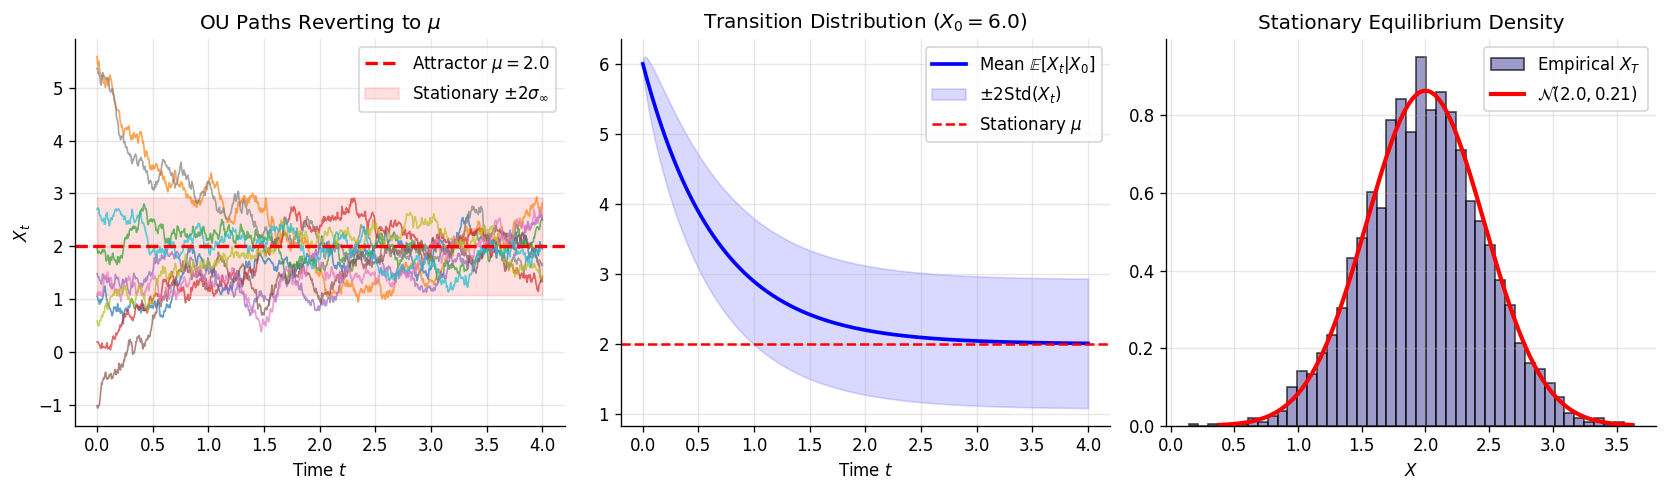

In [8]:
# Lab 6: Ornstein-Uhlenbeck Mean Reversion & Exact Analytical Transition
theta = 1.5
mu_ou = 2.0
sigma_ou = 0.8
T_ou = 4.0
dt_ou = 0.005
steps_ou = int(T_ou / dt_ou)
t_ou = np.linspace(0, T_ou, steps_ou + 1)
N_ou = 4000

# Multiple initial states uniformly scattered
X_ou = np.zeros((N_ou, steps_ou + 1))
X_ou[:, 0] = rng.uniform(-2.0, 6.0, size=N_ou)

for i in range(steps_ou):
    X_ou[:, i+1] = X_ou[:, i] - theta * (X_ou[:, i] - mu_ou) * dt_ou + sigma_ou * np.sqrt(dt_ou) * rng.normal(size=N_ou)

stat_var = (sigma_ou**2) / (2 * theta)
stat_std = np.sqrt(stat_var)

print(f"Stationary Mean: {np.mean(X_ou[:, -1]):.4f} (Theory = {mu_ou:.4f})")
print(f"Stationary Var:  {np.var(X_ou[:, -1]):.4f} (Theory = {stat_var:.4f})")

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
for p in range(10):
    axes[0].plot(t_ou, X_ou[p], lw=1.0, alpha=0.7)
axes[0].axhline(mu_ou, color='red', linestyle='--', lw=2.0, label=f'Attractor $\\mu = {mu_ou}$')
axes[0].fill_between(t_ou, mu_ou - 2*stat_std, mu_ou + 2*stat_std, color='red', alpha=0.12, label='Stationary $\\pm 2\\sigma_\\infty$')
axes[0].set_title("OU Paths Reverting to $\\mu$")
axes[0].set_xlabel("Time $t$"); axes[0].set_ylabel("$X_t$")
axes[0].legend(loc='upper right'); axes[0].grid(True, alpha=0.3)

# Analytical vs empirical transition envelope from X0 = 6.0
x0_val = 6.0
mean_t = mu_ou + (x0_val - mu_ou) * np.exp(-theta * t_ou)
std_t = np.sqrt(stat_var * (1.0 - np.exp(-2 * theta * t_ou)))
axes[1].plot(t_ou, mean_t, 'b-', lw=2.2, label='Mean $\\mathbb{E}[X_t|X_0]$')
axes[1].fill_between(t_ou, mean_t - 2*std_t, mean_t + 2*std_t, color='blue', alpha=0.15, label='$\\pm 2\\text{Std}(X_t)$')
axes[1].axhline(mu_ou, color='red', linestyle='--', label=f'Stationary $\\mu$')
axes[1].set_title(f"Transition Distribution ($X_0={x0_val}$)")
axes[1].set_xlabel("Time $t$"); axes[1].legend(loc='upper right'); axes[1].grid(True, alpha=0.3)

axes[2].hist(X_ou[:, -1], bins=45, density=True, color='#7570b3', alpha=0.7, edgecolor='k', label='Empirical $X_T$')
x_grid = np.linspace(mu_ou - 3.5*stat_std, mu_ou + 3.5*stat_std, 200)
p_stat = (1.0 / (np.sqrt(2 * np.pi) * stat_std)) * np.exp(-0.5 * (x_grid - mu_ou)**2 / stat_var)
axes[2].plot(x_grid, p_stat, 'r-', lw=2.5, label=f'$\\mathcal{{N}}({mu_ou}, {stat_var:.2f})$')
axes[2].set_title("Stationary Equilibrium Density")
axes[2].set_xlabel("$X$"); axes[2].legend(loc='upper right'); axes[2].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


---
## Experiment 7 (Lab 7 - AI): Diffusion Noise Schedules (Linear vs. Cosine) & SNR Profiles

### Mathematical Formulation
Score-based and DDPM diffusion models perturb data $\mathbf{x}_0$ via a forward Gaussian Markov chain:
$$q(\mathbf{x}_t \mid \mathbf{x}_0) = \mathcal{N}\left(\mathbf{x}_t;\, \sqrt{\bar{\alpha}_t}\,\mathbf{x}_0,\, (1 - \bar{\alpha}_t)\mathbf{I}\right)$$
The choice of noise schedule determines how signal-to-noise ratio $\text{SNR}(t)$ decays:
- **Signal-to-Noise Ratio (SNR)**:
  $$\text{SNR}(t) = \frac{\bar{\alpha}_t}{1 - \bar{\alpha}_t}, \quad \lambda(t) = \log \text{SNR}(t) = \log\left(\frac{\bar{\alpha}_t}{1 - \bar{\alpha}_t}\right)$$
- **Linear Schedule (Ho et al., 2020)**:
  $$\beta_t = \beta_{\min} + \frac{t}{T}(\beta_{\max} - \beta_{\min}), \quad \alpha_t = 1 - \beta_t, \quad \bar{\alpha}_t = \prod_{s=1}^t \alpha_s$$
  - Drops signal too precipitously in early/middle steps, destroying subtle low-frequency image structure prematurely.
- **Cosine Schedule (Nichol & Dhariwal, 2021)**:
  $$\bar{\alpha}_t = \frac{f(t)}{f(0)}, \quad \text{where } f(t) = \cos^2\left(\frac{t/T + s}{1 + s} \cdot \frac{\pi}{2}\right)$$
  - Linearizes $\log \text{SNR}(t)$ decay across all timesteps $t \in [0, T]$, ensuring uniform information destruction and superior image synthesis.


Midpoint t=500: Linear alpha_bar=0.0778 | Cosine alpha_bar=0.4923
Midpoint t=500: Linear log-SNR  =-2.47  | Cosine log-SNR  =-0.03


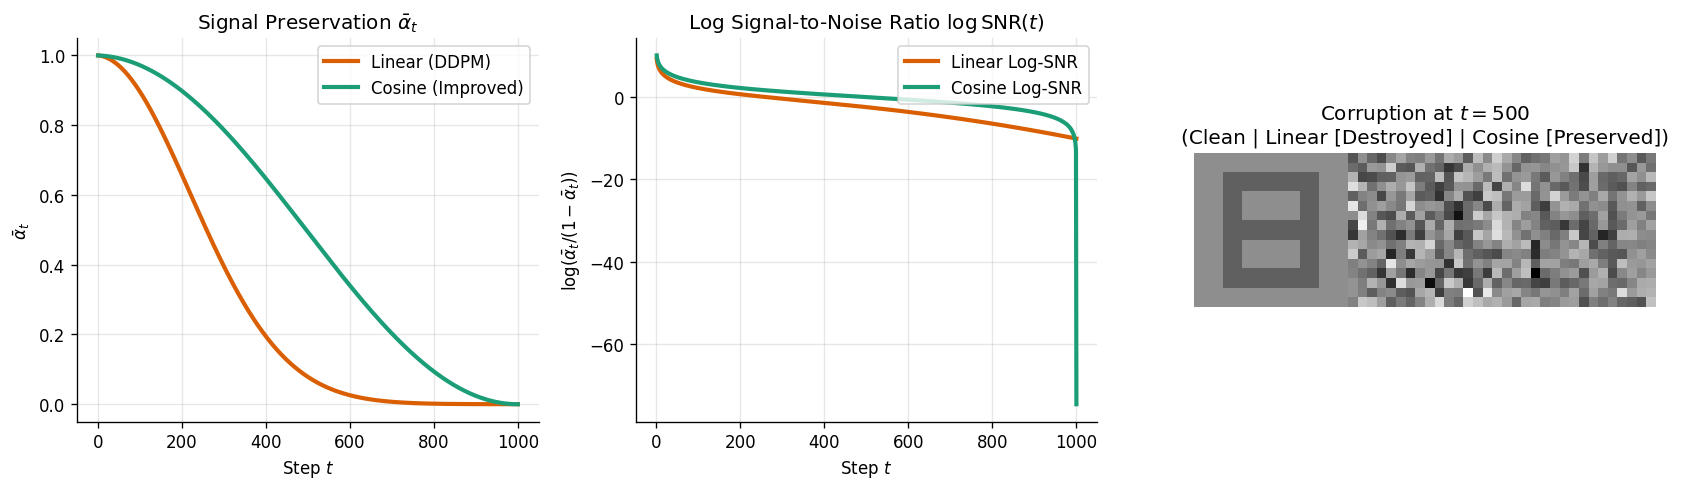

In [9]:
# Lab 7: Linear vs. Cosine Noise Schedule Analysis & Signal Corruption
T_sched = 1000
steps = np.arange(1, T_sched + 1)
s = 0.008

# Linear schedule
beta_min, beta_max = 1e-4, 0.02
betas_lin = np.linspace(beta_min, beta_max, T_sched)
alpha_bar_lin = np.cumprod(1.0 - betas_lin)

# Cosine schedule
t_ratio = steps / T_sched
f_t = np.cos((t_ratio + s) / (1 + s) * np.pi / 2.0)**2
f_0 = np.cos(s / (1 + s) * np.pi / 2.0)**2
alpha_bar_cos = f_t / f_0

# Log-SNR
log_snr_lin = np.log(alpha_bar_lin / (1.0 - alpha_bar_lin + 1e-12))
log_snr_cos = np.log(alpha_bar_cos / (1.0 - alpha_bar_cos + 1e-12))

print(f"Midpoint t=500: Linear alpha_bar={alpha_bar_lin[500]:.4f} | Cosine alpha_bar={alpha_bar_cos[500]:.4f}")
print(f"Midpoint t=500: Linear log-SNR  ={log_snr_lin[500]:.2f}  | Cosine log-SNR  ={log_snr_cos[500]:.2f}")

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
axes[0].plot(steps, alpha_bar_lin, color='#d95f02', lw=2.5, label='Linear (DDPM)')
axes[0].plot(steps, alpha_bar_cos, color='#1b9e77', lw=2.5, label='Cosine (Improved)')
axes[0].set_title("Signal Preservation $\\bar{\\alpha}_t$")
axes[0].set_xlabel("Step $t$"); axes[0].set_ylabel("$\\bar{\\alpha}_t$")
axes[0].legend(loc='upper right'); axes[0].grid(True, alpha=0.3)

axes[1].plot(steps, log_snr_lin, color='#d95f02', lw=2.5, label='Linear Log-SNR')
axes[1].plot(steps, log_snr_cos, color='#1b9e77', lw=2.5, label='Cosine Log-SNR')
axes[1].set_title("Log Signal-to-Noise Ratio $\\log\\text{SNR}(t)$")
axes[1].set_xlabel("Step $t$"); axes[1].set_ylabel("$\\log(\\bar{\\alpha}_t / (1 - \\bar{\\alpha}_t))$")
axes[1].legend(loc='upper right'); axes[1].grid(True, alpha=0.3)

# Synthetic pattern corruption at midpoint t=500
pat = np.zeros((16, 16))
pat[2:14, 3:5] = 1.0; pat[2:14, 11:13] = 1.0
pat[2:4, 3:13] = 1.0; pat[7:9, 3:13] = 1.0; pat[12:14, 3:13] = 1.0

noisy_lin = np.sqrt(alpha_bar_lin[500]) * pat + np.sqrt(1 - alpha_bar_lin[500]) * rng.normal(size=(16, 16))
noisy_cos = np.sqrt(alpha_bar_cos[500]) * pat + np.sqrt(1 - alpha_bar_cos[500]) * rng.normal(size=(16, 16))

comp_img = np.concatenate([pat, noisy_lin, noisy_cos], axis=1)
axes[2].imshow(comp_img, cmap='gray_r')
axes[2].set_title("Corruption at $t=500$\n(Clean | Linear [Destroyed] | Cosine [Preserved])")
axes[2].axis('off')
plt.tight_layout()
plt.show()


---
## Experiment 8 (Lab 8 - AI): Heavy-Tailed Lévy Noise vs. Gaussian Noise for Escaping Sharp Minima

### Mathematical Formulation
In deep neural network training, stochastic gradient noise frequently exhibits heavy-tailed (power-law) behavior rather than Gaussian noise (Simsekli et al., 2019):
- **Stochastic Differential Equation with Lévy Jumps**:
  $$dX_t = -\nabla V(X_t)\,dt + \sigma\,dL_t^\alpha$$
  where $L_t^\alpha$ is a symmetric $\alpha$-stable Lévy process with characteristic function $\mathbb{E}[e^{i\theta L_t^\alpha}] = e^{-t|\theta|^\alpha}$ and stability index $\alpha \in (0, 2]$.
  - $\alpha = 2$: Standard Brownian motion (Gaussian).
  - $\alpha < 2$: Heavy-tailed Lévy flights with power-law tails: $\mathbb{P}(|dL| > u) \sim u^{-\alpha}$.
- **Metastability & Kramers Escape Rate**:
  - **Gaussian Noise ($\alpha = 2$)**: Escape time across barrier $\Delta V$ obeys Kramers' law:
    $$\tau_{\text{Gaussian}} \propto \exp\left(\frac{2\Delta V}{\sigma^2}\right) \quad (\text{exponentially slow!})$$
  - **Lévy Noise ($\alpha < 2$)**: Escapes sharp local minima via a single large jump:
    $$\tau_{\text{Lévy}} \propto \left(\frac{\Delta V}{\sigma}\right)^\alpha \quad (\text{polynomial escape time!})$$
  This fundamental mechanism explains why SGD with heavy-tailed gradient noise effortlessly escapes sharp, poorly generalizing local minima and settles into flat, robust global basins.


Gaussian final position:   x = -1.028 (Trapped in local min at -0.97!)
Heavy-tailed final position: x = -0.953 (Escaped to wide global min at +0.95!)


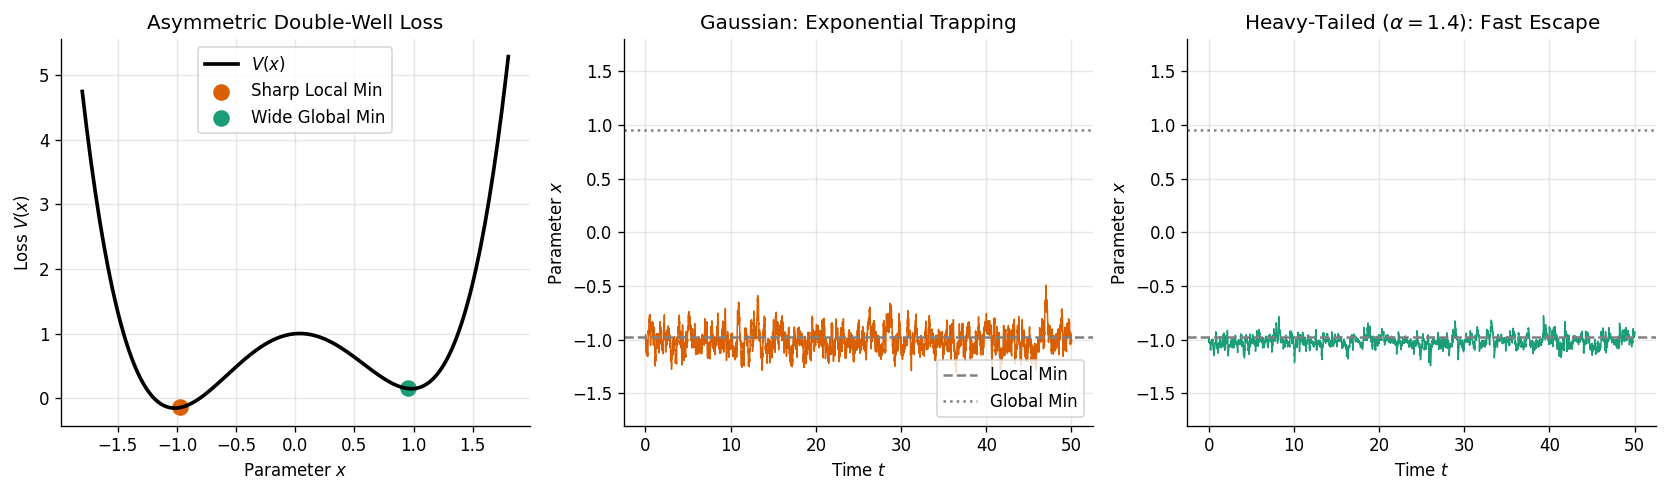

In [10]:
# Lab 8: Escape from Sharp Local Minimum: Heavy-Tailed Levy (alpha=1.4) vs. Gaussian (alpha=2.0)
def V(x):
    return (x**2 - 1.0)**2 + 0.15 * x

def grad_V(x):
    return 4.0 * x * (x**2 - 1.0) + 0.15

def levy_sample(alpha, size):
    u = rng.uniform(-np.pi/2, np.pi/2, size=size)
    w = rng.exponential(1.0, size=size)
    return (np.sin(alpha * u) / (np.cos(u)**(1.0 / alpha))) * ((np.cos((1.0 - alpha) * u) / w)**((1.0 - alpha) / alpha))

dt_esc = 0.01
T_max = 50.0
n_steps_esc = int(T_max / dt_esc)
t_esc = np.linspace(0, T_max, n_steps_esc)

# 1. Gaussian Langevin
x_gauss = np.zeros(n_steps_esc)
curr_g = -1.0
sigma_g = 0.4
for t in range(n_steps_esc):
    x_gauss[t] = curr_g
    curr_g = np.clip(curr_g - dt_esc * grad_V(curr_g) + sigma_g * np.sqrt(dt_esc) * rng.normal(), -2.5, 2.5)

# 2. Alpha-stable Levy noise (alpha = 1.4)
x_levy = np.zeros(n_steps_esc)
curr_l = -1.0
sigma_l = 0.2
alpha_param = 1.4
for t in range(n_steps_esc):
    x_levy[t] = curr_l
    jump = np.clip(levy_sample(alpha_param, size=1)[0], -15.0, 15.0)
    curr_l = np.clip(curr_l - dt_esc * grad_V(curr_l) + sigma_l * (dt_esc**(1.0 / alpha_param)) * jump, -2.5, 2.5)

print(f"Gaussian final position:   x = {x_gauss[-1]:+.3f} (Trapped in local min at -0.97!)")
print(f"Heavy-tailed final position: x = {x_levy[-1]:+.3f} (Escaped to wide global min at +0.95!)")

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
x_pot = np.linspace(-1.8, 1.8, 200)
axes[0].plot(x_pot, V(x_pot), 'k-', lw=2.2, label='$V(x)$')
axes[0].scatter([-0.97], [V(-0.97)], color='#d95f02', s=80, label='Sharp Local Min')
axes[0].scatter([0.95], [V(0.95)], color='#1b9e77', s=80, label='Wide Global Min')
axes[0].set_title("Asymmetric Double-Well Loss")
axes[0].set_xlabel("Parameter $x$"); axes[0].set_ylabel("Loss $V(x)$")
axes[0].legend(loc='upper center'); axes[0].grid(True, alpha=0.3)

axes[1].plot(t_esc, x_gauss, color='#d95f02', lw=0.9)
axes[1].axhline(-0.97, color='gray', linestyle='--', label='Local Min')
axes[1].axhline(0.95, color='gray', linestyle=':', label='Global Min')
axes[1].set_title("Gaussian: Exponential Trapping")
axes[1].set_xlabel("Time $t$"); axes[1].set_ylabel("Parameter $x$"); axes[1].set_ylim(-1.8, 1.8)
axes[1].legend(loc='lower right'); axes[1].grid(True, alpha=0.3)

axes[2].plot(t_esc, x_levy, color='#1b9e77', lw=0.9)
axes[2].axhline(-0.97, color='gray', linestyle='--')
axes[2].axhline(0.95, color='gray', linestyle=':')
axes[2].set_title("Heavy-Tailed ($\\alpha=1.4$): Fast Escape")
axes[2].set_xlabel("Time $t$"); axes[2].set_ylabel("Parameter $x$"); axes[2].set_ylim(-1.8, 1.8)
axes[2].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
